In [73]:
import numpy as np
import sep

In [74]:
from astropy.io import fits
import matplotlib.pyplot as plt
from matplotlib import rcParams

%matplotlib inline

#set consistent canvas size
rcParams['figure.figsize'] = [10.,8.]

In [75]:
#define file name
image = '/Users/user/Desktop/astr19 final/hlsp_hudf12_hst_wfc3ir_udfmain_f105w_v1.0_drz.fits'

# read image into standard 2d numpy array
#read in data
hdu_1 = fits.open(image)

#get image data
data_1 = hdu_1[0].data


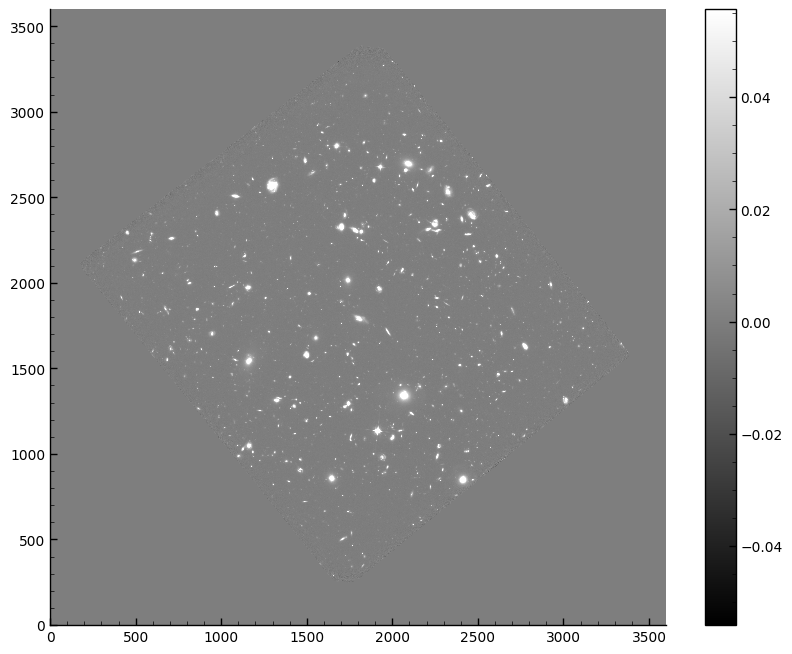

In [76]:
# show image 
m, s = np.mean(data_1), np.std(data_1)
plt.imshow(data_1, interpolation='nearest', cmap='gray' , vmin=m-s, vmax=m+s, origin='lower')
plt.colorbar();

# plt.savefig('tutorial_im-1.png')

# Background Subtraction

In [77]:
# measure a spatially varying background on the image

data_1 = data_1.astype(data_1.dtype.newbyteorder('='))

bkg = sep.Background(data_1)

In [78]:
# get a "global" mean and noise of the image background:
print(bkg.globalback)
print(bkg.globalrms)

0.0
0.0005398219218477607


In [79]:
# evaluate background as 2-d array, same size as original image
bkg_image = bkg.back()


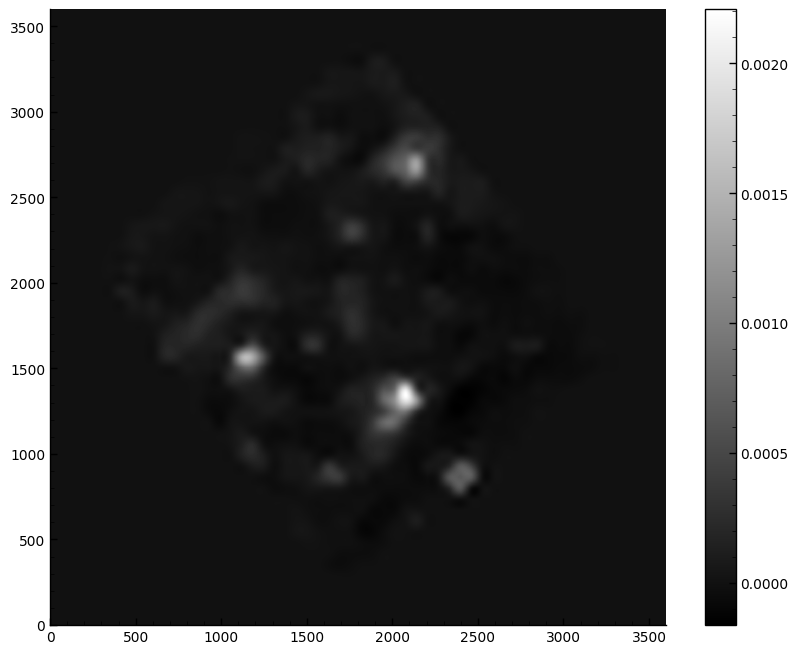

In [80]:
# show the background
plt.imshow(bkg_image, interpolation='nearest', cmap='gray', origin='lower')
plt.colorbar();

In [81]:
# evaluate the background noise as 2-d array, same size as original image
bkg_rms = bkg.rms()

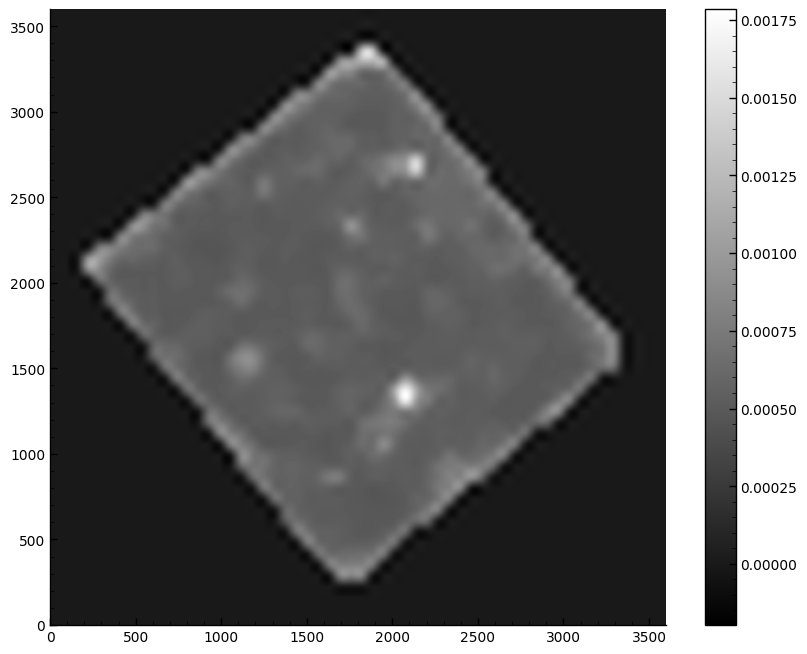

In [82]:
# show background noise
plt.imshow(bkg_rms, interpolation='nearest', cmap='gray',origin='lower')
plt.colorbar();

In [83]:
# subtract the background
data_sub = data_1 - bkg

In [84]:
objects = sep.extract(data_sub, 1.5, err=bkg.globalrms)

# Found 8640 Sources

In [85]:
# how many objects were detected
len(objects)

8640

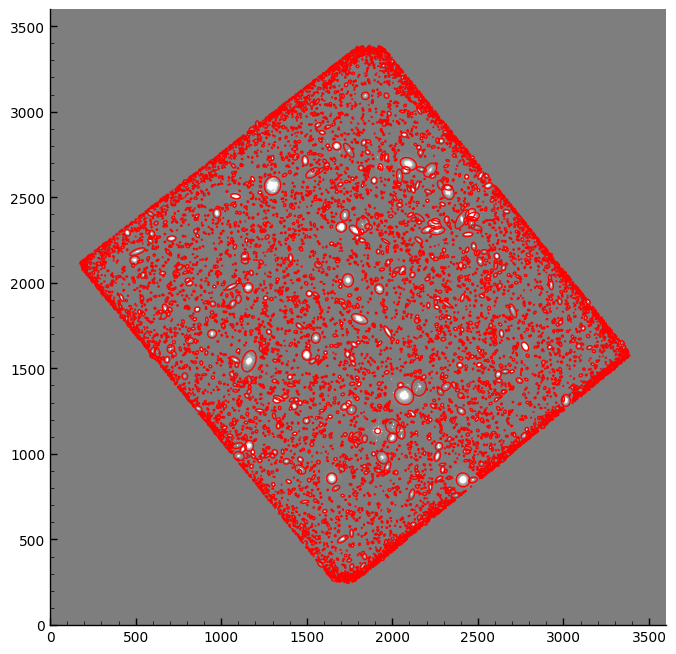

In [86]:
from matplotlib.patches import Ellipse

# plot backgroundsubtracted image
fig, ax = plt.subplots()
m, s = np.mean(data_sub), np.std(data_sub)
im = ax.imshow(data_sub, interpolation='nearest', cmap='gray', vmin=m-s, vmax=m+s, origin='lower')

# plot an ellipse for each object
for i in range(len(objects)):
    e = Ellipse(xy=(objects['x'][i], objects['y'][i]),
                width=6*objects['a'][i],
                height=6*objects['b'][i],
                angle=objects['theta'][i] * 180. / np.pi)
    e.set_facecolor('none')
    e.set_edgecolor('red')
    ax.add_artist(e)

In [87]:
flux, fluxerr, flag = sep.sum_circle(data_sub, objects['x'], objects['y'],
                                    3.0, err=bkg.globalrms, gain=1.0)

In [88]:
# show the first 10 objects results:
for i in range(10):
    print("object {:d}: flux = {:f} +/- {:f}".format(i,flux[i], fluxerr[i]))

object 0: flux = 0.031282 +/- 0.176890
object 1: flux = 0.031018 +/- 0.176142
object 2: flux = -0.024388 +/- 0.002883
object 3: flux = 0.001947 +/- 0.044219
object 4: flux = 0.012457 +/- 0.111649
object 5: flux = -0.011228 +/- 0.002875
object 6: flux = 0.029368 +/- 0.171394
object 7: flux = -0.009126 +/- 0.002875
object 8: flux = 0.048023 +/- 0.219161
object 9: flux = 0.027840 +/- 0.166877


# Histogram Flux

Text(0.5, 1.0, 'Flux Distribution')

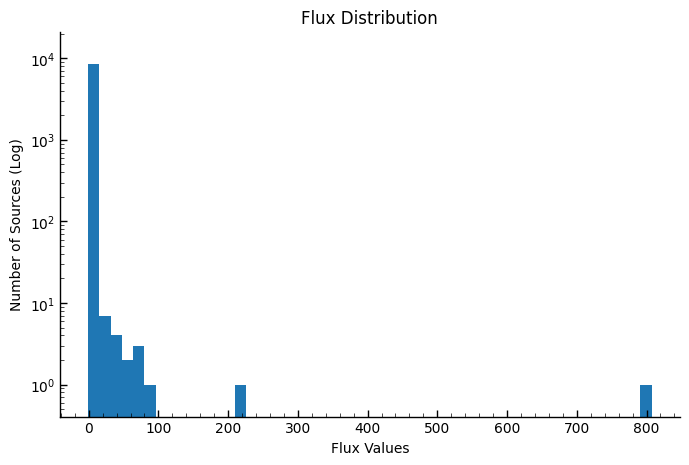

In [89]:
plt.style.use("./astr19_matplotlib_defaults.txt")

plt.figure(figsize=[8, 5])
plt.hist(flux, bins=50, log = True)
plt.ylabel('Number of Sources (Log)')
plt.xlabel('Flux Values')
plt.title('Flux Distribution')

In [90]:
print(f'The mean of the distribution of fluxes is {np.mean(flux)}')
print(f'The median of the distribution of fluxes is {np.median(flux)}')
print(f'The standard deviation of the distribution of fluxes is {np.std(flux)}')

The mean of the distribution of fluxes is 0.3618620007201894
The median of the distribution of fluxes is 0.03095655805023853
The standard deviation of the distribution of fluxes is 9.243527842777791


# Finding the largest outlier

In [91]:
largest_outlier_index1 = np.argmax(flux)
largest_outlier_index1

np.int64(2066)

# Where it is:

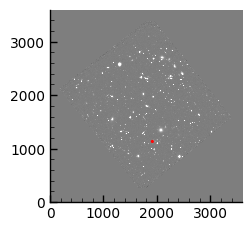

In [92]:
# plot background subtracted image
fig, ax = plt.subplots()
m, s = np.mean(data_sub), np.std(data_sub)
im = ax.imshow(data_sub, interpolation='nearest', cmap='gray', vmin=m-s, vmax=m+s, origin='lower')

# plot a red ellipse for the outlier
e = Ellipse(xy=(objects[2066]['x'], objects[2066]['y']),
            width=6*objects[2066]['a'],
            height=6*objects[2066]['b'],
            angle=objects[2066]['theta'] * 180. / np.pi)
e.set_facecolor('none')
e.set_edgecolor('red')
ax.add_artist(e)

# Standard Deviations

In [93]:
#finding largest outlier's value
largest_outlier_value = np.max(flux)

#calculating residual
residual = largest_outlier_value - (np.mean(flux))

# calculating how many standard deviations away the outlier's value is 
# from the data's mean
standard_deviation = residual/(np.std(flux))
print(f'The outlier is {standard_deviation} standard deviations away from the mean')


The outlier is 87.2973431029269 standard deviations away from the mean


# 3-Color False Image

In [94]:
# defining file names

fdata_105w = 'astr19 final/hlsp_hudf12_hst_wfc3ir_udfmain_f105w_v1.0_drz.fits'
fdata_125w = 'astr19 final/hlsp_hudf12_hst_wfc3ir_udfmain_f125w_v1.0_drz.fits'
fdata_160w = 'astr19 final/hlsp_hudf12_hst_wfc3ir_udfmain_f160w_v1.0_drz.fits'

In [95]:
# reading in data

hdu_2 = fits.open(fdata_105w)
hdu_3 = fits.open(fdata_125w)
hdu_4 = fits.open(fdata_160w)

# getting the image data

data_2 = hdu_2[0].data
data_3 = hdu_3[0].data
data_4 = hdu_4[0].data

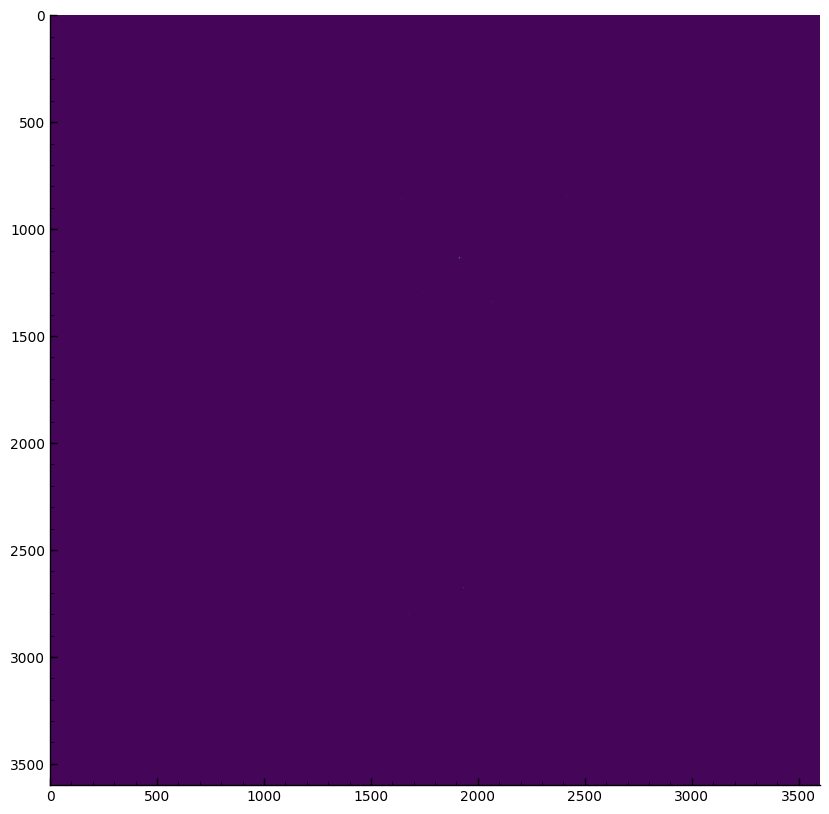

In [96]:
# checking unscaled image
f = plt.figure(figsize=(10,10))
plt.imshow(data_2)

## creating a rescaling function to use on each data file

In [97]:
def rescale_image(data):
    data_copy = data.copy()
    # m = the mean of the copied data, ignoring NaN values
    m = np.nanmean(data_copy)
    # setting visual limit but dividing mean in half
    vplmin = m/2
    vpmin = np.log10(vplmin)
    vpmax = np.log10(m*100.)

    # slicing out the part of data_copy that's less than vplmin and setting them to vplmin's value
    data_copy[data_copy<vplmin] = vplmin
    # logarithmic stretch; seeing fainter pixels easier
    data_copy = np.log10(data_copy)
    return data_copy,vpmin,vpmax

In [98]:
# rescaling each array and returning new variables frome each

data_2_res, d2min, d2max = rescale_image(data_2)
data_3_res, d3min, d3max = rescale_image(data_3)
data_4_res, d4min, d4max = rescale_image(data_4)

In [99]:
# initializing final array 
rgb = np.zeros((data_2_res.shape[0], data_2_res.shape[1],3))

#normalizing data to be between 0 and 1
rgb[:,:,0] = (data_2_res-d2min)/(d2max-d2min)
rgb[:,:,1] = (data_3_res-d3min)/(d3max-d3min)
rgb[:,:,2] = (data_4_res-d4min)/(d4max-d4min)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..2.2922489643096924].


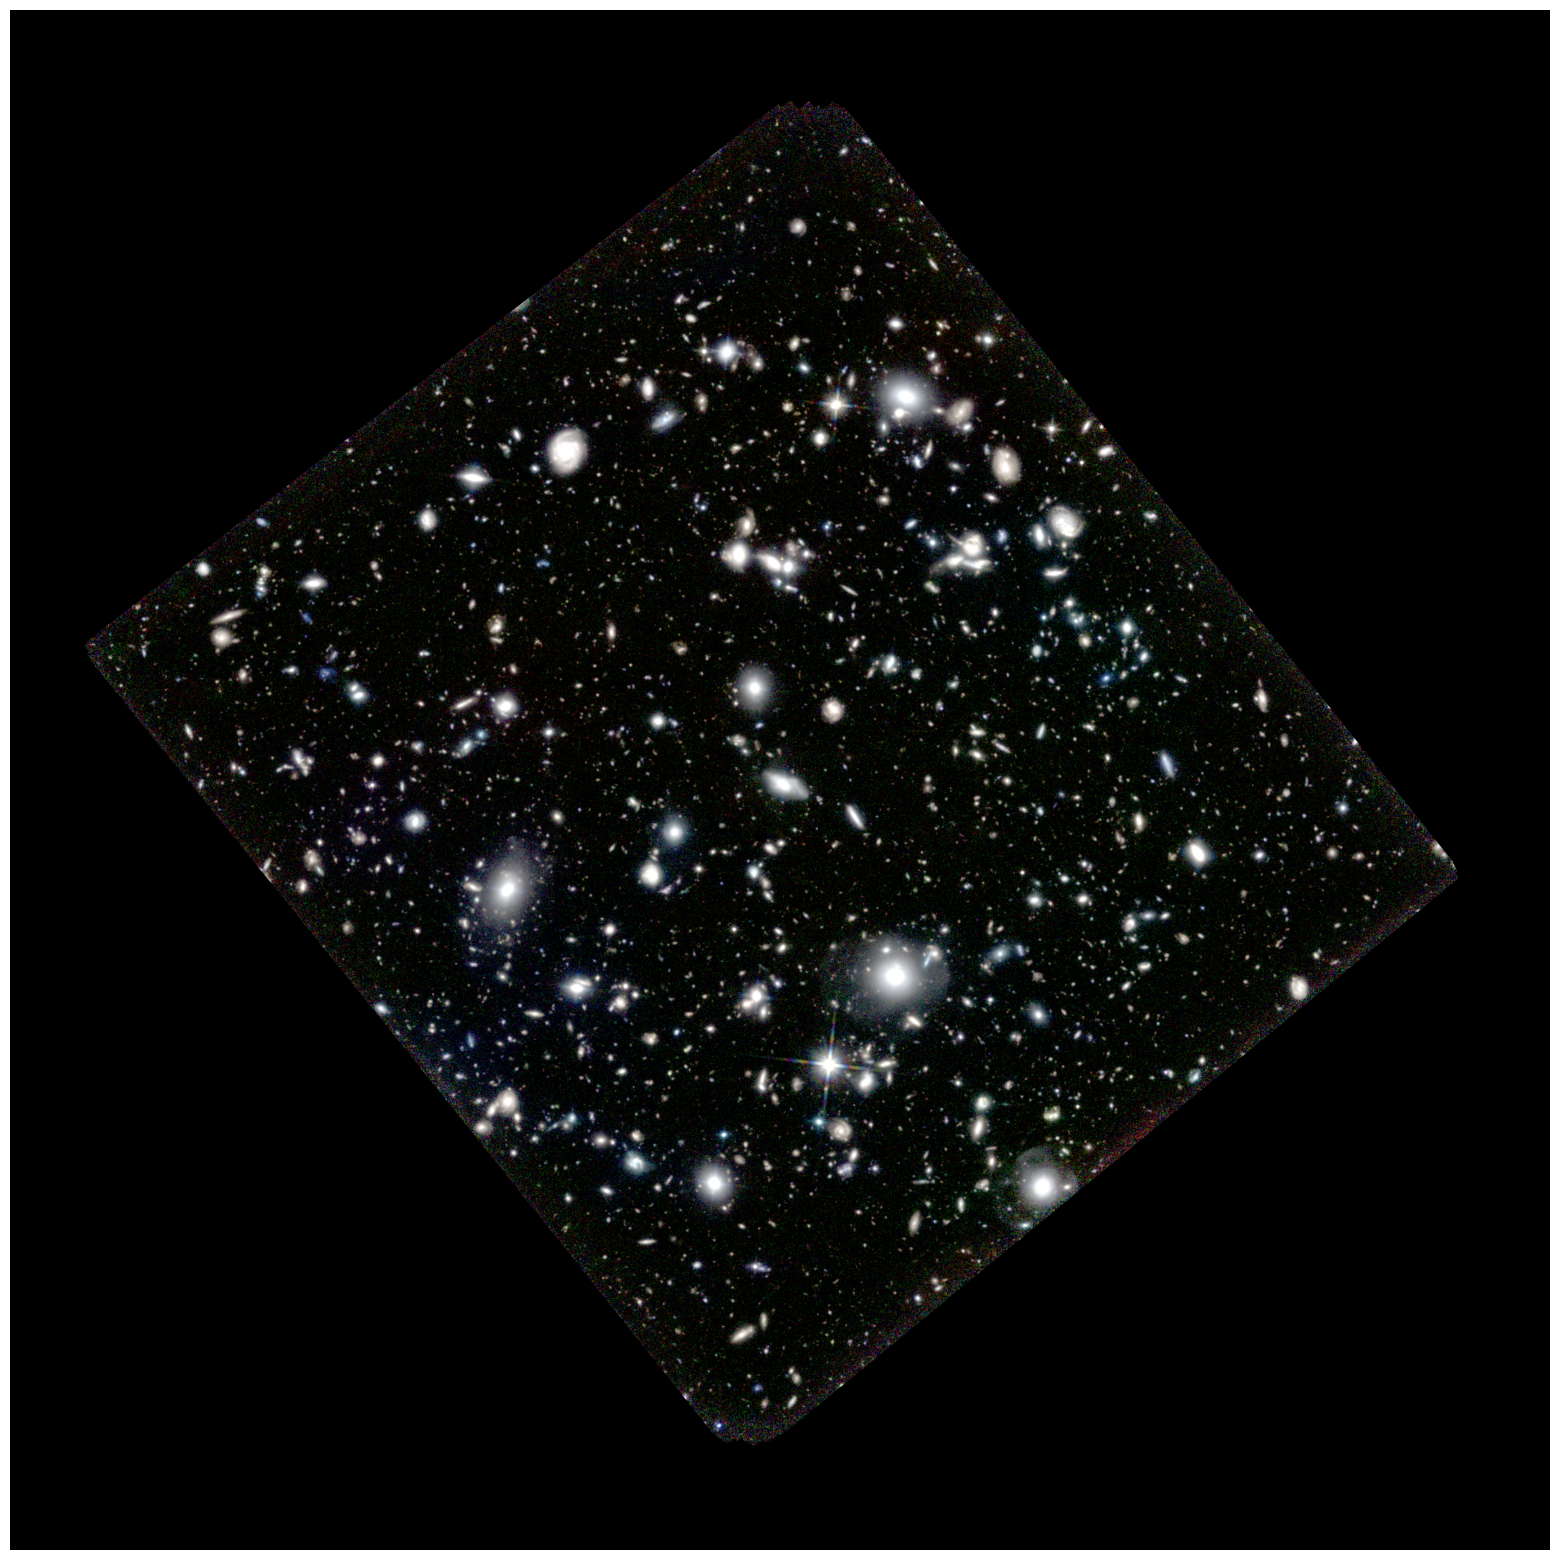

In [100]:
f,ax = plt.subplots(1,1,figsize=(20,20))
ax.axis('off')
ax.imshow(rgb, origin='lower')
plt.savefig('3-colors_image.png',bbox_inches='tight',pad_inches=0,dpi=600)